# Experiment 08 — Coordination-weighted (3×) validation diagnostics

Evaluate **TensorNequIP-NMR-Coord3x-9083627**, the saved best checkpoint, on **50 validation structures only**. Training labels supply the elemental-mean baseline and shielding-coverage comparison; training predictions are not computed. No test dataset or old prediction cache is loaded.

The target is absolute isotropic magnetic shielding, `MS_Iso_QM = trace(ms)/3`, in ppm, one scalar per site. This is not a full-tensor or experimental chemical-shift evaluation.

These are development diagnostics for identifying improvements. This validation set already selected the checkpoint, so its errors and bootstrap intervals are not an independent final performance assessment. Bootstrap intervals are descriptive, conditional on this checkpoint and supplied split; they do not account for selection or training-seed variability.

Run all cells using the project's `.venv` Python. Existing model and dataset files are read only. All structure and atom indices are zero-based.


In [1]:
from pathlib import Path
from importlib.metadata import version
from datetime import datetime, timezone
import hashlib
import json
import os
import platform
import sys
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import yaml
from ase.io import read
from graph_pes.atomic_graph import AtomicGraph
from graph_pes.utils.nn import count_used_parameters
from IPython.display import display, Markdown

RUN_NAME = 'TensorNequIP-NMR-Coord3x-9083627'
candidates = ([Path(os.environ['NEQUIP_PROJECT'])] if 'NEQUIP_PROJECT' in os.environ else [])
candidates += [Path.cwd(), *Path.cwd().parents,
               Path('/Users/louismcauliffe/code/research/NequIP_experiments')]
PROJECT = next((p.resolve() for p in candidates
                if (p / 'graph-pes-results' / RUN_NAME / 'model.pt').is_file()), None)
if PROJECT is None:
    raise FileNotFoundError('Set NEQUIP_PROJECT to the NequIP_experiments directory.')
sys.path.insert(0, str(PROJECT))
# Required to unpickle the trusted local model; importing does not generate data.
import extract_ms_isotropy

RUN = PROJECT / 'graph-pes-results' / RUN_NAME
SPLITS = ['train', 'valid']
ELEMENTS = ['Si', 'O']
COLOURS = {'Si': '#2769a4', 'O': '#d56831'}
PATHS = {split: PROJECT / 'data/nmr_iso' / f'{split}.xyz' for split in SPLITS}
THREADS = 2
torch.set_num_threads(THREADS)
torch.set_default_dtype(torch.float32)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 10})
pd.set_option('display.max_columns', 20)
pd.set_option('display.width', 160)

def sha256(path):
    with open(path, 'rb') as stream:
        return hashlib.file_digest(stream, 'sha256').hexdigest()

versions = {name: version(name) for name in ['graph-pes', 'torch', 'e3nn', 'ase', 'numpy', 'pandas']}
print('Project:', PROJECT)
print('Inference: CPU, float32,', THREADS, 'threads |', platform.machine())
print('Versions:', versions)


Project: /Users/louismcauliffe/code/research/NequIP_experiments
Inference: CPU, float32, 2 threads | arm64
Versions: {'graph-pes': '1.0.2', 'torch': '2.6.0', 'e3nn': '0.4.4', 'ase': '3.29.0', 'numpy': '2.4.6', 'pandas': '3.0.6'}


## 1. Checkpoint and training provenance

Check the exported model against `best.ckpt` before inference, including its saved offsets and scales. The final-epoch summary is not the best checkpoint's accuracy. Epoch numbers are displayed starting at one.


In [2]:
def same_state(a, b):
    if isinstance(a, torch.Tensor):
        return isinstance(b, torch.Tensor) and torch.equal(a, b)
    if isinstance(a, dict):
        return isinstance(b, dict) and a.keys() == b.keys() and all(same_state(v, b[k]) for k, v in a.items())
    if isinstance(a, (list, tuple)):
        return type(a) is type(b) and len(a) == len(b) and all(same_state(x, y) for x, y in zip(a, b))
    return a == b

config = yaml.safe_load((RUN / 'train-config.yaml').read_text())
summary = yaml.safe_load((RUN / 'summary.yaml').read_text())
best = torch.load(RUN / 'checkpoints/best.ckpt', map_location='cpu', weights_only=False)
last = torch.load(RUN / 'checkpoints/last.ckpt', map_location='cpu', weights_only=False)
model = torch.load(RUN / 'model.pt', map_location='cpu', weights_only=False)
best_state = {k.removeprefix('model.'): v for k, v in best['state_dict'].items() if k.startswith('model.')}
assert same_state(best_state, model.state_dict()), 'Export does not match best checkpoint.'
assert all(torch.isfinite(v).all() for v in best_state.values()
           if isinstance(v, torch.Tensor) and v.is_floating_point())
training_parameter_count = sum(p.numel() for p in model.parameters() if p.requires_grad)
model.eval().requires_grad_(False)
assert next(model.parameters()).dtype == torch.float32
best_epoch, last_epoch = int(best['epoch']) + 1, int(last['epoch']) + 1
loss_config = config['loss']['isotropy']['+coordination_loss.CoordinationWeightedMSE']
assert loss_config['defect_weight'] == 3.0 and loss_config['coordination_cutoff'] == 2.2
loss_weight = float(loss_config['weight'])
assert config['data'].get('test') is None
for split in ['train', 'valid']:
    assert config['data'][split]['property_map'] == {'MS_Iso_QM': 'tensor'}
    assert (PROJECT / config['data'][split]['path']).resolve() == PATHS[split].resolve()

provenance = {
    'Run': RUN_NAME, 'Best epoch (1-based)': best_epoch,
    'Last epoch (1-based)': last_epoch, 'Best global step': int(best['global_step']),
    'Export matches best checkpoint': True,
    'Learnable parameters': training_parameter_count,
    'Cutoff (Å)': float(model.cutoff), 'Training loss': f'{loss_weight:g} × coordination-weighted shielding MSE (defects 3×); validation unweighted',
    'Saved best validation MSE (ppm²)': float(summary['early_stopping/best_valid_loss']) / loss_weight,
    'Final-epoch validation MSE (ppm²)': float(summary['valid/metrics/coordination_mse']),
    'Physical batch size': config['fitting']['loader_kwargs']['batch_size'],
    'Gradient accumulation': config['fitting']['trainer_kwargs'].get('accumulate_grad_batches', 1),
}
display(pd.Series(provenance, name='Value').to_frame())
model_hash = sha256(RUN / 'model.pt')
del best, last, best_state


,Value
Run,TensorNequIP-NMR-Coord3x-9083627
Best epoch (1-based),287
Last epoch (1-based),300
Best global step,57400
Export matches best checkpoint,True
Learnable parameters,753262
Cutoff (Å),6.0
Training loss,1000 × coordination-weighted shielding MSE (de...
Saved best validation MSE (ppm²),3.409656
Final-epoch validation MSE (ppm²),3.633816


## 2. Audit training and validation labels

Check ppm units and every scalar label against `trace(ms)/3`. Screen for duplicate geometries within and between training and validation. Rounded coordinate fingerprints are not a symmetry-aware similarity search and cannot establish independence of related MD snapshots. Trajectory identifiers are unavailable.


In [3]:
structures = {split: read(path, index=':', format='extxyz') for split, path in PATHS.items()}
data_hashes = {split: sha256(path) for split, path in PATHS.items()}

def geometry_key(atoms):
    digest = hashlib.sha256()
    for array in [np.asarray(atoms.numbers, dtype='<i8'),
                  np.round(atoms.positions, 6).astype('<f8'),
                  np.round(atoms.cell.array, 6).astype('<f8'), atoms.pbc.astype('u1')]:
        digest.update(np.ascontiguousarray(array).tobytes())
    return digest.hexdigest()

audit_rows, fingerprint_sets = [], {}
for split, frames in structures.items():
    assert frames, f'Empty {split} split'
    max_trace_error = 0.0
    fingerprints = []
    for frame in frames:
        labels = np.asarray(frame.arrays['MS_Iso_QM'], dtype=np.float64)
        tensors = np.asarray(frame.arrays['ms'], dtype=np.float64).reshape(len(frame), 3, 3)
        expected = np.trace(tensors, axis1=1, axis2=2) / 3
        assert labels.shape == (len(frame),) and np.isfinite(labels).all()
        assert frame.info['magres_units']['ms'] == 'ppm'
        assert set(frame.get_chemical_symbols()) <= set(ELEMENTS)
        max_trace_error = max(max_trace_error, float(np.max(np.abs(labels - expected))))
        assert np.allclose(labels, expected, rtol=0, atol=1e-7)
        fingerprints.append(geometry_key(frame))
    fingerprint_sets[split] = set(fingerprints)
    row = {'split': split, 'structures': len(frames), 'sites': sum(map(len, frames)),
           'duplicate_frames': len(frames) - len(set(fingerprints)),
           'max_trace_error_ppm': max_trace_error}
    for element in ELEMENTS:
        row[element + '_sites'] = sum(np.sum(np.array(f.get_chemical_symbols()) == element) for f in frames)
    audit_rows.append(row)
audit = pd.DataFrame(audit_rows).set_index('split')
display(audit)
overlap = pd.DataFrame([{'split_A': a, 'split_B': b,
                         'shared_geometries': len(fingerprint_sets[a] & fingerprint_sets[b])}
                        for a, b in [('train', 'valid')]])
display(overlap)
assert overlap['shared_geometries'].sum() == 0, 'Split overlap: do not claim held-out accuracy.'
assert audit['duplicate_frames'].sum() == 0, 'Repeated structures need explicit treatment.'


,structures,sites,duplicate_frames,max_trace_error_ppm,Si_sites,O_sites
split,,,,,,
train,800,115200,0,3.333412e-09,38400,76800
valid,50,7200,0,3.333412e-09,2400,4800


,split_A,split_B,shared_geometries
0,train,valid,0


## 3. Fresh validation inference

Predict only the validation structures, using species, geometry and periodicity. Reference labels are excluded from model inputs. No fitting, referencing correction or cached predictions are used. Training labels are retained only for baseline and coverage calculations.


In [4]:
def predict_split(frames):
    predictions = []
    started = time.perf_counter()
    for index, atoms in enumerate(frames):
        graph = AtomicGraph.from_ase(atoms, cutoff=float(model.cutoff))
        assert not graph.properties and not graph.other, 'Reference labels entered model inputs.'
        with torch.no_grad():
            values = model.predict(graph, ['tensor'])['tensor'].cpu().numpy().copy()
        assert values.shape == (len(atoms),) and np.isfinite(values).all()
        predictions.append(values)
        if (index + 1) % 100 == 0 or index + 1 == len(frames):
            print(f'{index + 1}/{len(frames)} structures complete', flush=True)
    return np.concatenate(predictions), time.perf_counter() - started

predictions, timings = {}, {}
with torch.no_grad():
    model.predict(AtomicGraph.from_ase(structures['valid'][0], cutoff=float(model.cutoff)), ['tensor'])
predictions['valid'], timings['valid'] = predict_split(structures['valid'])
rows = []
for split, frames in structures.items():
    start = 0
    for frame_index, atoms in enumerate(frames):
        count = len(atoms)
        rows.append(pd.DataFrame({
            'split': split, 'structure_index': frame_index, 'atom_index': np.arange(count),
            'element': atoms.get_chemical_symbols(),
            'reference_ppm': np.asarray(atoms.arrays['MS_Iso_QM'], dtype=np.float64),
            'prediction_ppm': predictions[split][start:start+count] if split == 'valid' else np.full(count, np.nan),
        }))
        start += count
sites = pd.concat(rows, ignore_index=True)
sites['error_ppm'] = sites['prediction_ppm'] - sites['reference_ppm']
sites['absolute_error_ppm'] = sites['error_ppm'].abs()
assert sites.loc[sites.split.eq('train'), 'prediction_ppm'].isna().all()
assert sites.loc[sites.split.eq('valid'), 'prediction_ppm'].notna().all()
print(f"Fresh validation inference: {timings['valid']:.2f} seconds for {len(structures['valid'])} structures.")


50/50 structures complete
Fresh validation inference: 16.07 seconds for 50 structures.


## 4. Site-level errors, reported separately for Si and O

For each element and split, $e_i=\hat\sigma_i-\sigma_i$:

$$\mathrm{MAE}=\frac{1}{n}\sum_i|e_i|,\qquad
\mathrm{RMSE}=\sqrt{\frac{1}{n}\sum_i e_i^2},\qquad
\mathrm{bias}=\frac{1}{n}\sum_i e_i.$$

$$R^2=1-\frac{\sum_i e_i^2}{\sum_i(\sigma_i-\bar\sigma)^2}.$$

Errors are in ppm; $R^2$ is dimensionless and is **not** squared Pearson correlation. Every site of the selected element contributes equally. The 95th percentile and maximum absolute errors show the tails. No outliers are removed.

The constant baseline uses **only the training-set mean of each element**. A percentage reduction in RMSE measures improvement over that baseline, not over a published ML model.


In [5]:
def score(reference, predicted):
    reference, predicted = np.asarray(reference, dtype=np.float64), np.asarray(predicted, dtype=np.float64)
    assert reference.shape == predicted.shape and reference.size > 0
    error = predicted - reference
    absolute = np.abs(error)
    denominator = np.sum((reference - reference.mean()) ** 2)
    result = {
        'MAE_ppm': float(absolute.mean()), 'RMSE_ppm': float(np.sqrt(np.mean(error ** 2))),
        'bias_ppm': float(error.mean()), 'median_AE_ppm': float(np.median(absolute)),
        'p95_AE_ppm': float(np.quantile(absolute, 0.95)), 'max_AE_ppm': float(absolute.max()),
        'R2': float(1 - np.sum(error ** 2) / denominator) if denominator > 0 else np.nan,
    }
    assert result['RMSE_ppm'] + 1e-12 >= result['MAE_ppm']
    return result

train_means = sites[sites['split'].eq('train')].groupby('element')['reference_ppm'].mean()
metric_rows = []
for split in ['valid']:
    for element in ELEMENTS:
        group = sites[sites['split'].eq(split) & sites['element'].eq(element)]
        scores = score(group['reference_ppm'], group['prediction_ppm'])
        baseline = score(group['reference_ppm'], np.full(len(group), train_means[element]))
        metric_rows.append({'split': split, 'element': element, 'sites': len(group),
                            'structures': group['structure_index'].nunique(), **scores,
                            'baseline_RMSE_ppm': baseline['RMSE_ppm'],
                            'baseline_MAE_ppm': baseline['MAE_ppm'],
                            'RMSE_reduction_vs_baseline_pct': 100 * (1 - scores['RMSE_ppm'] / baseline['RMSE_ppm'])})
metrics = pd.DataFrame(metric_rows).set_index(['split', 'element'])
print('Primary result — validation set:')
display(metrics.loc['valid'].round(4))
print('Validation errors by element:')
display(metrics[['MAE_ppm', 'RMSE_ppm', 'bias_ppm', 'R2']].round(4))
print('Training-only elemental-mean baseline (ppm):', train_means.round(4).to_dict())

# Check against the saved validation loss, which pools all sites and both elements.
pooled_mse = sites.groupby('split')['error_ppm'].agg(lambda x: float(np.mean(x.to_numpy() ** 2)))
logged_best_mse = float(summary['early_stopping/best_valid_loss']) / loss_weight
relative_discrepancy = abs(pooled_mse['valid'] - logged_best_mse) / logged_best_mse
assert relative_discrepancy < 0.005, 'Validation reconstruction differs from the saved best loss by >0.5%.'
print(f"Recomputed best validation MSE: {pooled_mse['valid']:.6f} ppm²; saved: {logged_best_mse:.6f} ppm²")
print(f'CPU versus training discrepancy: {100 * relative_discrepancy:.5f}%')
print('The training weight of 1000 is not applied to any accuracy metric above.')


Primary result — validation set:
Validation errors by element:
Training-only elemental-mean baseline (ppm): {'O': 201.5273, 'Si': 436.0872}
Recomputed best validation MSE: 3.409727 ppm²; saved: 3.409656 ppm²
CPU versus training discrepancy: 0.00207%
The training weight of 1000 is not applied to any accuracy metric above.


,sites,structures,MAE_ppm,RMSE_ppm,bias_ppm,median_AE_ppm,p95_AE_ppm,max_AE_ppm,R2,baseline_RMSE_ppm,baseline_MAE_ppm,RMSE_reduction_vs_baseline_pct
element,,,,,,,,,,,,
Si,2400,50,0.5295,0.9967,0.0224,0.3240,1.5962,12.9462,0.9879,9.0632,7.1323,89.0033
O,4800,50,1.0484,2.1489,0.0128,0.6079,3.2034,34.1242,0.9895,20.9806,14.0895,89.7575


MAE_ppm  RMSE_ppm  bias_ppm      R2
split element                                     
valid Si        0.5295    0.9967    0.0224  0.9879
      O         1.0484    2.1489    0.0128  0.9895

## 5. Descriptive validation sampling uncertainty

Resample 50 whole validation structures 2,000 times, keeping sites together. These percentile intervals describe sampling variation conditional on the selected model. They assume independent structures, exclude training-seed variability, and do not correct for using validation to select the checkpoint. They are not prediction intervals for individual sites.


In [6]:
validation_sites = sites[sites['split'].eq('valid')]
rng = np.random.default_rng(42)
bootstrap_rows = []
for element in ELEMENTS:
    group = validation_sites[validation_sites['element'].eq(element)]
    aggregate = group.groupby('structure_index')['error_ppm'].agg(
        n='size', sum_absolute=lambda x: float(np.abs(x).sum()),
        sum_squared=lambda x: float(np.square(x).sum()), sum_signed='sum')
    draws = rng.integers(0, len(aggregate), size=(2000, len(aggregate)))
    counts = aggregate['n'].to_numpy()[draws].sum(axis=1)
    boot_mae = aggregate['sum_absolute'].to_numpy()[draws].sum(axis=1) / counts
    boot_rmse = np.sqrt(aggregate['sum_squared'].to_numpy()[draws].sum(axis=1) / counts)
    boot_bias = aggregate['sum_signed'].to_numpy()[draws].sum(axis=1) / counts
    for metric, samples in [('MAE_ppm', boot_mae), ('RMSE_ppm', boot_rmse), ('bias_ppm', boot_bias)]:
        low, high = np.quantile(samples, [0.025, 0.975])
        bootstrap_rows.append({'element': element, 'metric': metric,
                               'estimate_ppm': metrics.loc[('valid', element), metric],
                               'lower_95_ppm': low, 'upper_95_ppm': high})
intervals = pd.DataFrame(bootstrap_rows).set_index(['element', 'metric'])
display(intervals.round(4))

def stats_box(ax, text, x=0.97, y=0.96, ha='right', fontsize=9):
    return ax.text(x, y, text, transform=ax.transAxes, va='top', ha=ha,
                   fontsize=fontsize, linespacing=1.45, zorder=10,
                   bbox={'facecolor': 'white', 'alpha': 0.94,
                         'edgecolor': '#d0d5db', 'boxstyle': 'round,pad=0.5'})

def ci_text(element, metric, signed=False):
    ci = intervals.loc[(element, metric)]
    fmt = '+.3f' if signed else '.3f'
    return f'{ci.lower_95_ppm:{fmt}} to {ci.upper_95_ppm:{fmt}}'


estimate_ppm  lower_95_ppm  upper_95_ppm
element metric                                            
Si      MAE_ppm         0.5295        0.4061        0.6880
        RMSE_ppm        0.9967        0.6017        1.3884
        bias_ppm        0.0224       -0.0163        0.0559
O       MAE_ppm         1.0484        0.8062        1.3354
        RMSE_ppm        2.1489        1.3587        2.9228
        bias_ppm        0.0128       -0.0765        0.1262

## 6. Validation-set parity and residuals

The parity diagonal is perfect agreement, not a fitted regression. Confidence intervals (CI) use the structure bootstrap above. Signed error is **prediction minus reference**: a positive bias means overprediction of shielding.

Histogram annotations give the bias with its confidence interval, residual standard deviation (SD, population definition), and median signed error. Residual-scatter annotations quantify tail errors. The largest 1% of absolute errors are highlighted; all sites remain included. Neither SD nor the 95th-percentile absolute error is a confidence interval.


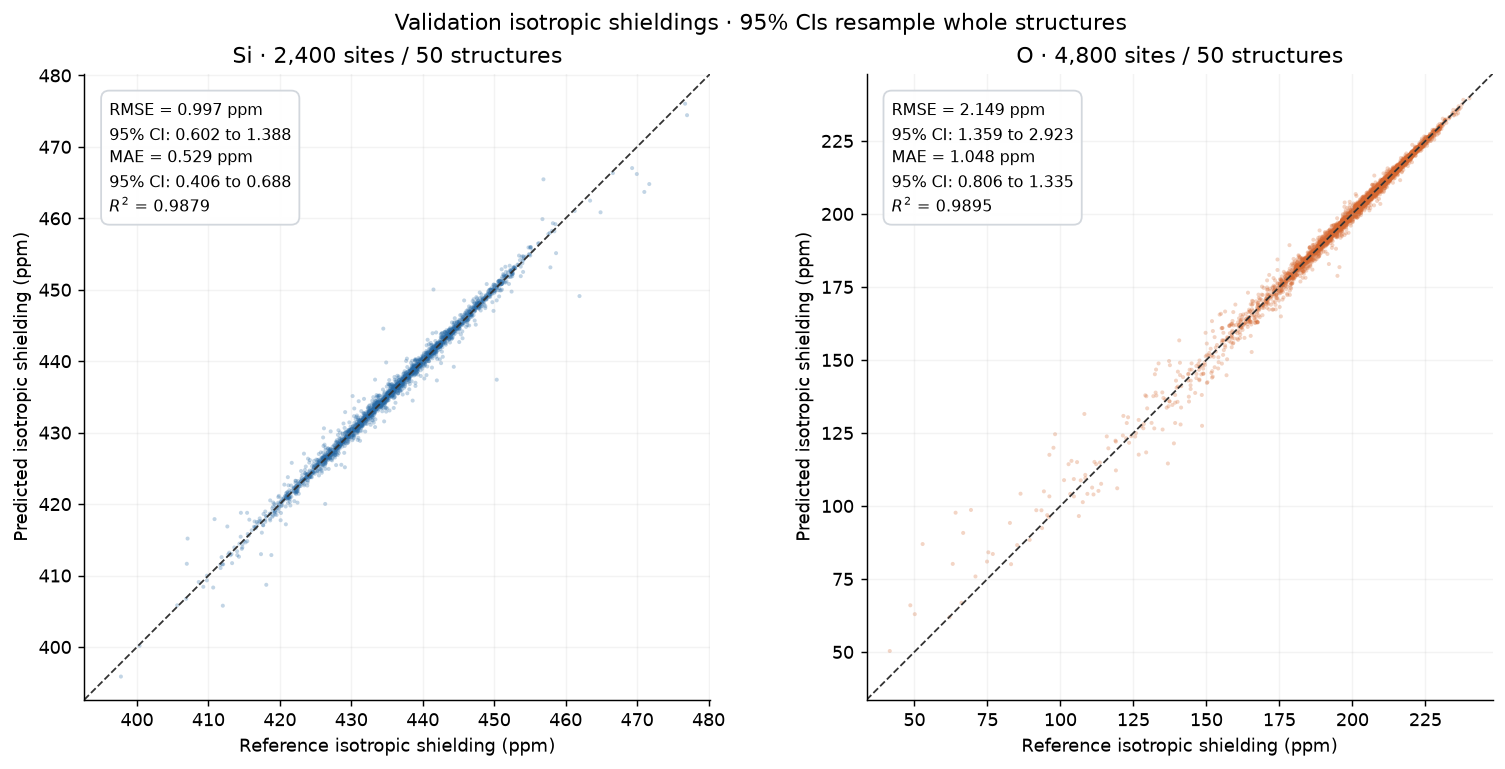

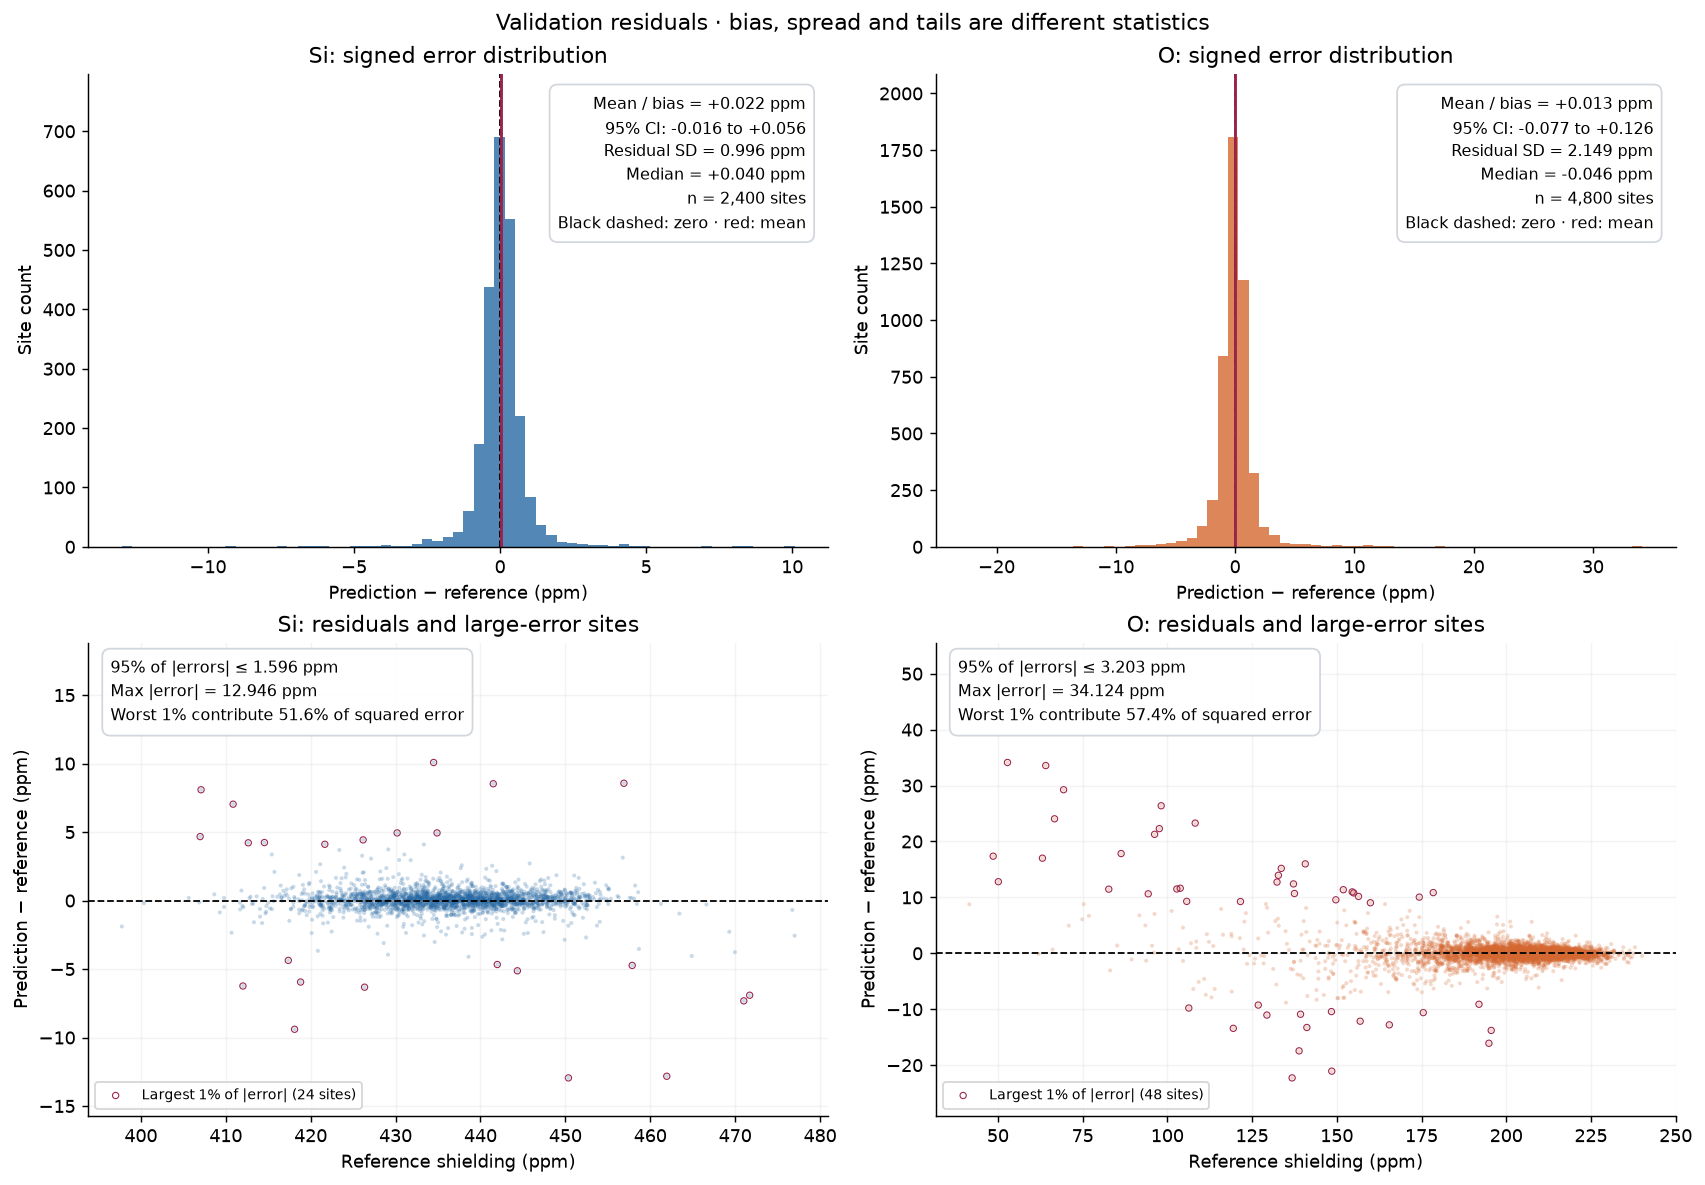

In [7]:
fig_parity, axes = plt.subplots(1, 2, figsize=(12, 5.8), layout='constrained')
for ax, element in zip(axes, ELEMENTS):
    group = validation_sites[validation_sites['element'].eq(element)]
    ref, pred = group['reference_ppm'].to_numpy(), group['prediction_ppm'].to_numpy()
    low, high = min(ref.min(), pred.min()), max(ref.max(), pred.max())
    margin = max(0.04 * (high - low), 0.1)
    limits = [low - margin, high + margin]
    ax.scatter(ref, pred, s=5, alpha=0.28, color=COLOURS[element], edgecolors='none', rasterized=True)
    ax.plot(limits, limits, '--', color='#333333', lw=1)
    ax.set(xlim=limits, ylim=limits, xlabel='Reference isotropic shielding (ppm)',
           ylabel='Predicted isotropic shielding (ppm)', title=f'{element} · {len(group):,} sites / {group.structure_index.nunique()} structures')
    ax.set_aspect('equal', adjustable='box')
    m = metrics.loc[('valid', element)]
    stats_box(ax, f'RMSE = {m.RMSE_ppm:.3f} ppm\n95% CI: {ci_text(element, "RMSE_ppm")}\n'
                 f'MAE = {m.MAE_ppm:.3f} ppm\n95% CI: {ci_text(element, "MAE_ppm")}\n'
                 f'$R^2$ = {m.R2:.4f}', x=0.04, ha='left')
    ax.grid(alpha=0.15)
fig_parity.suptitle('Validation isotropic shieldings · 95% CIs resample whole structures')
plt.show()

fig_residuals, axes = plt.subplots(2, 2, figsize=(13, 9), layout='constrained')
for column, element in enumerate(ELEMENTS):
    group = validation_sites[validation_sites['element'].eq(element)]
    error = group['error_ppm'].to_numpy()
    m = metrics.loc[('valid', element)]
    ax = axes[0, column]
    ax.hist(error, bins=65, color=COLOURS[element], alpha=0.8)
    ax.axvline(0, color='black', linestyle='--', lw=1)
    ax.axvline(m.bias_ppm, color='#9a244b', lw=1.6)
    stats_box(ax, f'Mean / bias = {m.bias_ppm:+.3f} ppm\n'
                 f'95% CI: {ci_text(element, "bias_ppm", signed=True)}\n'
                 f'Residual SD = {error.std(ddof=0):.3f} ppm\n'
                 f'Median = {np.median(error):+.3f} ppm\n'
                 f'n = {len(error):,} sites\nBlack dashed: zero · red: mean', fontsize=9)
    ax.set(title=f'{element}: signed error distribution', xlabel='Prediction − reference (ppm)', ylabel='Site count')
    ax.set_ylim(0, ax.get_ylim()[1] * 1.1)

    ax = axes[1, column]
    tail_count = int(np.ceil(0.01 * len(error)))
    tail_positions = np.argsort(np.abs(error))[-tail_count:]
    tail_fraction = np.sum(error[tail_positions] ** 2) / np.sum(error ** 2)
    ax.scatter(group['reference_ppm'], error, s=5, alpha=0.25,
               color=COLOURS[element], edgecolors='none', rasterized=True)
    ax.scatter(group['reference_ppm'].to_numpy()[tail_positions], error[tail_positions], s=12,
               facecolors='none', edgecolors='#9a244b', linewidths=0.6,
               label=f'Largest 1% of |error| ({tail_count} sites)', rasterized=True)
    ax.axhline(0, color='black', linestyle='--', lw=1)
    stats_box(ax, f'95% of |errors| ≤ {m.p95_AE_ppm:.3f} ppm\n'
                 f'Max |error| = {m.max_AE_ppm:.3f} ppm\n'
                 f'Worst 1% contribute {100 * tail_fraction:.1f}% of squared error',
              x=0.03, y=0.97, ha='left', fontsize=9)
    ax.set(title=f'{element}: residuals and large-error sites', xlabel='Reference shielding (ppm)',
           ylabel='Prediction − reference (ppm)')
    lo, hi = error.min(), error.max()
    ax.set_ylim(lo - 0.12 * (hi - lo), hi + 0.38 * (hi - lo))
    ax.legend(loc='lower left', fontsize=8)
    ax.grid(alpha=0.15)
fig_residuals.suptitle('Validation residuals · bias, spread and tails are different statistics')
plt.show()


## 7. Validation accuracy and shielding coverage

Compare validation errors with a constant predictor using each element's training mean. Compare training and validation label distributions without running predictions on training structures. Label-range overlap does not establish structural similarity.


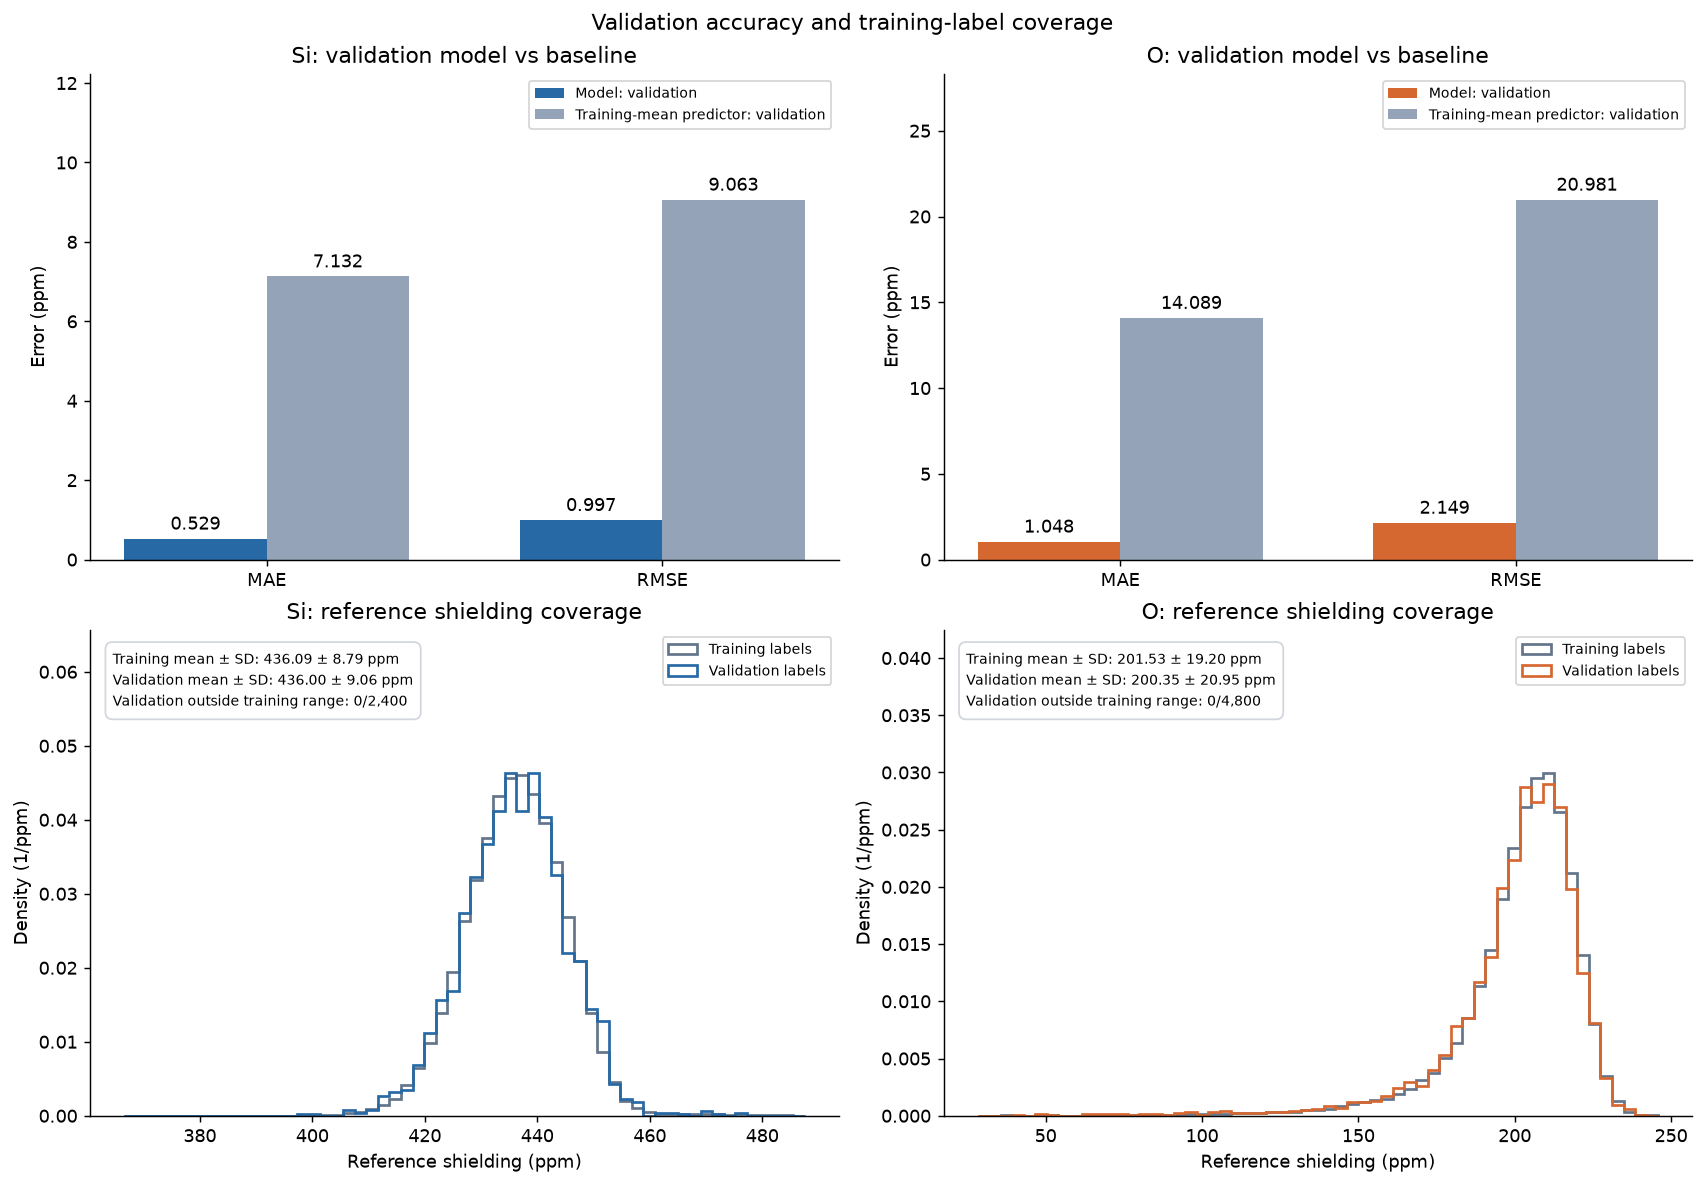

,train_min_ppm,train_max_ppm,validation_min_ppm,validation_max_ppm,validation_sites_outside_training_range
element,,,,,
Si,366.547,487.530,397.757,476.994,0
O,28.290,245.859,41.573,240.087,0


In [8]:
fig_splits, axes = plt.subplots(2, 2, figsize=(13, 9), layout='constrained')
coverage_rows = []
for col, element in enumerate(ELEMENTS):
    ax = axes[0, col]
    m = metrics.loc[('valid', element)]
    x = np.arange(2)
    values = [m.MAE_ppm, m.RMSE_ppm]
    baseline = [m.baseline_MAE_ppm, m.baseline_RMSE_ppm]
    ax.bar(x-0.18, values, width=0.36, color=COLOURS[element], label='Model: validation')
    ax.bar(x+0.18, baseline, width=0.36, color='#94a3b8', label='Training-mean predictor: validation')
    for positions, numbers in [(x-0.18,values),(x+0.18,baseline)]:
        for pos, value in zip(positions,numbers):
            ax.annotate(f'{value:.3f}',(pos,value),xytext=(0,5),textcoords='offset points',ha='center')
    ax.set_xticks(x,['MAE','RMSE'])
    ax.set(title=f'{element}: validation model vs baseline',ylabel='Error (ppm)',ylim=(0,max(baseline+values)*1.35))
    ax.legend(fontsize=8)
    ax = axes[1,col]
    train = sites.loc[sites.split.eq('train') & sites.element.eq(element),'reference_ppm']
    valid = validation_sites.loc[validation_sites.element.eq(element),'reference_ppm']
    bins = np.linspace(min(train.min(),valid.min()),max(train.max(),valid.max()),60)
    for label, data, colour in [('Training labels',train,'#64748b'),('Validation labels',valid,COLOURS[element])]:
        ax.hist(data,bins=bins,density=True,histtype='step',lw=1.5,label=label,color=colour)
    outside = int(((valid<train.min()) | (valid>train.max())).sum())
    stats_box(ax,f'Training mean ± SD: {train.mean():.2f} ± {train.std(ddof=0):.2f} ppm\nValidation mean ± SD: {valid.mean():.2f} ± {valid.std(ddof=0):.2f} ppm\nValidation outside training range: {outside}/{len(valid):,}',x=0.03,ha='left',fontsize=8)
    ax.set(title=f'{element}: reference shielding coverage',xlabel='Reference shielding (ppm)',ylabel='Density (1/ppm)')
    ax.set_ylim(0,ax.get_ylim()[1]*1.35)
    ax.legend(loc='upper right',fontsize=8)
    coverage_rows.append({'element':element,'train_min_ppm':train.min(),'train_max_ppm':train.max(),
                         'validation_min_ppm':valid.min(),'validation_max_ppm':valid.max(),
                         'validation_sites_outside_training_range':outside})
fig_splits.suptitle('Validation accuracy and training-label coverage')
plt.show()
coverage = pd.DataFrame(coverage_rows).set_index('element')
display(coverage.round(3))


## 8. Structure-level variation and largest errors

Each point is one structure's RMSE. The dashed line gives RMSE across all validation sites; the shaded band is its 95% structure-bootstrap confidence interval. **The band is not a prediction interval for individual structures**: points outside it are not a test of statistical significance. Labels show the median and largest structure RMSE and identify the worst structure.

Overall site RMSE is computed from all squared site errors, not by averaging structure RMSEs. The table retains original structure/atom indices. No outliers are removed.


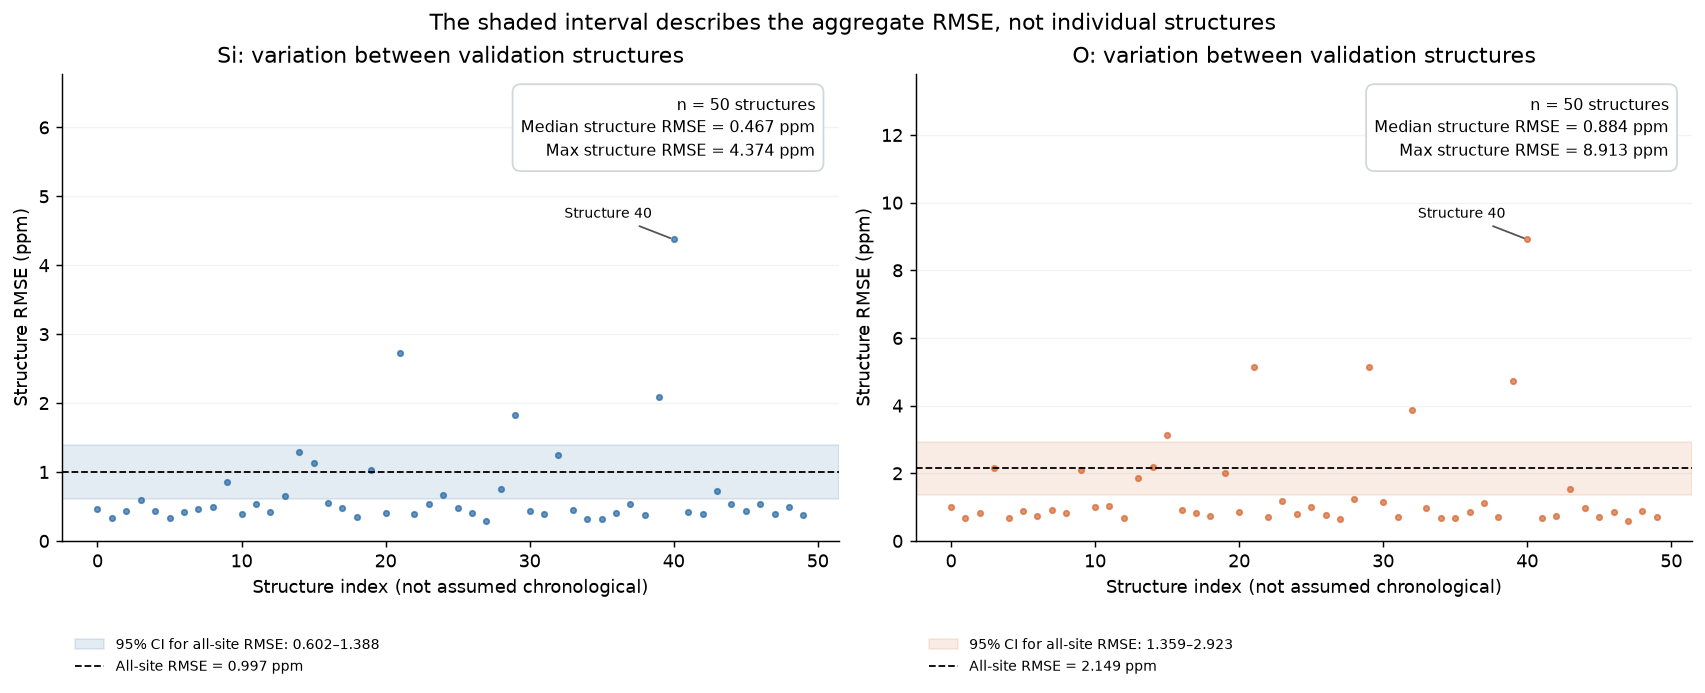

,element,structure_index,atom_index,reference_ppm,prediction_ppm,error_ppm
121073,Si,40,113,450.3575,437.4113,-12.9462
121088,Si,40,128,461.9409,449.1140,-12.8269
120957,Si,39,141,434.4809,444.5614,10.0805
118346,Si,21,122,418.1029,408.7057,-9.3972
121097,Si,40,137,456.8947,465.4573,8.5626
121055,O,40,95,52.8293,86.9535,34.1242
120977,O,40,17,64.1172,97.6885,33.5712
121032,O,40,72,69.3807,98.6327,29.2520
119464,O,29,88,98.1843,124.5695,26.3852
119895,O,32,87,66.7118,90.7653,24.0535


In [9]:
structure_rows = []
for (element, structure_index), group in validation_sites.groupby(['element', 'structure_index']):
    structure_rows.append({'element': element, 'structure_index': int(structure_index), 'sites': len(group),
                           **score(group['reference_ppm'], group['prediction_ppm'])})
structure_metrics = pd.DataFrame(structure_rows)
fig_structures, axes = plt.subplots(1, 2, figsize=(13, 5.2), layout='constrained')
for ax, element in zip(axes, ELEMENTS):
    group = structure_metrics[structure_metrics['element'].eq(element)]
    aggregate = metrics.loc[('valid', element), 'RMSE_ppm']
    ci = intervals.loc[(element, 'RMSE_ppm')]
    worst = group.loc[group['RMSE_ppm'].idxmax()]
    ax.axhspan(ci.lower_95_ppm, ci.upper_95_ppm, color=COLOURS[element], alpha=0.12,
               label=f'95% CI for all-site RMSE: {ci.lower_95_ppm:.3f}–{ci.upper_95_ppm:.3f}')
    ax.plot(group['structure_index'], group['RMSE_ppm'], 'o', ms=3, alpha=0.7, color=COLOURS[element])
    ax.axhline(aggregate, color='black', ls='--', lw=1,
               label=f'All-site RMSE = {aggregate:.3f} ppm')
    stats_box(ax, f'n = {len(group)} structures\nMedian structure RMSE = {group.RMSE_ppm.median():.3f} ppm\n'
                 f'Max structure RMSE = {worst.RMSE_ppm:.3f} ppm', fontsize=9)
    dx = -12 if worst.structure_index > len(structures['valid'])/2 else 12
    ax.annotate(f'Structure {int(worst.structure_index)}', (worst.structure_index, worst.RMSE_ppm),
                xytext=(dx, 12), textcoords='offset points', fontsize=8,
                ha='right' if dx < 0 else 'left', arrowprops={'arrowstyle':'-', 'color':'#555555'})
    ax.set(title=f'{element}: variation between validation structures', xlabel='Structure index (not assumed chronological)',
           ylabel='Structure RMSE (ppm)', ylim=(0, worst.RMSE_ppm * 1.55))
    ax.legend(loc='upper left', bbox_to_anchor=(0, -0.18), fontsize=8, frameon=False)
    ax.grid(axis='y', alpha=0.15)
fig_structures.suptitle('The shaded interval describes the aggregate RMSE, not individual structures')
plt.show()
worst_sites = pd.concat([validation_sites[validation_sites['element'].eq(el)].nlargest(5, 'absolute_error_ppm') for el in ELEMENTS])
display(worst_sites[['element','structure_index','atom_index','reference_ppm','prediction_ppm','error_ppm']].round(4))


## 9. Does coordination explain the large errors?

Count oxygen neighbours around Si and silicon neighbours around O within **2.2 Å**, including periodic boundaries. The common groups are Si with four O neighbours and O with two Si neighbours. The observed neighbour counts for each group are reported below; groups are recomputed from validation structures.

The figure puts **site-level RMSE beside the number and percentage of sites** in each group. This separates the question “how frequent is this environment?” from “how accurate are its predictions?”. Whiskers are descriptive 95% confidence intervals from 2,000 whole-structure bootstrap resamples, retaining within-structure dependence. They assume independent structures and do not include training-seed uncertainty. Rare-group estimates have fewer supporting structures.

**Interpretation:** these are exploratory, distance-based groups, not definitive bonding assignments. A stretched bond near the cutoff can change the count. The association does not prove coordination itself causes the errors, and some normally coordinated sites also have large errors. All validation sites remain included; no model fitting uses these labels. Edit `COORDINATION_CUTOFF` below to check threshold sensitivity.


In [10]:
from ase.neighborlist import neighbor_list

COORDINATION_CUTOFF = 2.2  # Å; provisional geometric criterion, not a universal bond definition.
coordination_rows = []
for structure_index, atoms in enumerate(structures['valid']):
    centre, neighbour, distance = neighbor_list('ijd', atoms, COORDINATION_CUTOFF)
    unlike = (atoms.numbers[centre] != atoms.numbers[neighbour]) & (distance < COORDINATION_CUTOFF)
    counts = np.bincount(centre[unlike], minlength=len(atoms))
    coordination_rows.append(pd.DataFrame({
        'structure_index': structure_index, 'atom_index': np.arange(len(atoms)),
        'opposite_element_neighbours': counts,
    }))
coordination_sites = validation_sites.merge(pd.concat(coordination_rows, ignore_index=True),
                                      on=['structure_index', 'atom_index'], validate='one_to_one')
assert len(coordination_sites) == len(validation_sites)
coordination_sites['group'] = np.where(
    coordination_sites['opposite_element_neighbours'].eq(coordination_sites['element'].map({'Si': 4, 'O': 2})),
    'Common coordination', 'Other coordination')

# Resample full structures, including those with zero sites from a particular group.
coord_rng = np.random.default_rng(42)
n_structures = len(structures['valid'])
coord_draws = coord_rng.integers(0, n_structures, size=(2000, n_structures))
coordination_results = []
for element in ELEMENTS:
    element_sites = coordination_sites[coordination_sites['element'].eq(element)]
    for name in ['Common coordination', 'Other coordination']:
        group = element_sites[element_sites['group'].eq(name)]
        assert len(group) > 0, f'No {element} sites in {name} at this cutoff.'
        by_structure = group.groupby('structure_index')['error_ppm'].agg(
            n='size', squared_error=lambda x: float(np.square(x).sum()))
        by_structure = by_structure.reindex(np.arange(n_structures), fill_value=0)
        sample_counts = by_structure['n'].to_numpy()[coord_draws].sum(axis=1)
        sample_sse = by_structure['squared_error'].to_numpy()[coord_draws].sum(axis=1)
        nonempty = sample_counts > 0
        bootstrap_rmse = np.sqrt(sample_sse[nonempty] / sample_counts[nonempty])
        low, high = np.quantile(bootstrap_rmse, [0.025, 0.975])
        coordination_results.append({
            'element': element, 'group': name,
            'observed_neighbour_counts': ', '.join(map(str, sorted(group.opposite_element_neighbours.unique()))),
            'sites': len(group), 'percent_of_element_sites': 100 * len(group) / len(element_sites),
            'structures_containing_group': group.structure_index.nunique(),
            **score(group.reference_ppm, group.prediction_ppm),
            'RMSE_CI_lower_ppm': low, 'RMSE_CI_upper_ppm': high,
            'nonempty_bootstrap_resamples': int(nonempty.sum()),
        })
coordination_metrics = pd.DataFrame(coordination_results).set_index(['element', 'group'])
print(f'Validation-site coordination groups: unlike neighbours within {COORDINATION_CUTOFF:.1f} Å.')
display(coordination_metrics[['observed_neighbour_counts', 'sites', 'percent_of_element_sites',
                              'structures_containing_group', 'MAE_ppm', 'RMSE_ppm',
                              'RMSE_CI_lower_ppm', 'RMSE_CI_upper_ppm']].round(3))

# Keep the exact coordination categories visible rather than hiding them in the pooled groups.
coordination_detail = pd.DataFrame([
    {'element': element, 'neighbours': int(count), 'sites': len(group),
     'structures': group.structure_index.nunique(),
     'MAE_ppm': group.absolute_error_ppm.mean(),
     'RMSE_ppm': np.sqrt(np.mean(group.error_ppm ** 2))}
    for (element, count), group in coordination_sites.groupby(['element', 'opposite_element_neighbours'])
]).set_index(['element', 'neighbours'])


Validation-site coordination groups: unlike neighbours within 2.2 Å.


observed_neighbour_counts  sites  percent_of_element_sites  structures_containing_group  MAE_ppm  RMSE_ppm  RMSE_CI_lower_ppm  \
element group                                                                                                                                               
Si      Common coordination                         4   2386                    99.417                           50    0.501     0.849              0.592   
        Other coordination                          5     14                     0.583                            5    5.464     6.878              0.580   
O       Common coordination                         2   4762                    99.208                           50    1.003     1.933              1.264   
        Other coordination                       1, 3     38                     0.792                           13    6.801    10.726              4.978   

                             RMSE_CI_upper_ppm  
element group                                   
Si      Common coordination              1.096  
        Other coordination               8.362  
O       Common coordination              2.567  
        Other coordination              13.183

Exact coordination categories (small groups require caution):


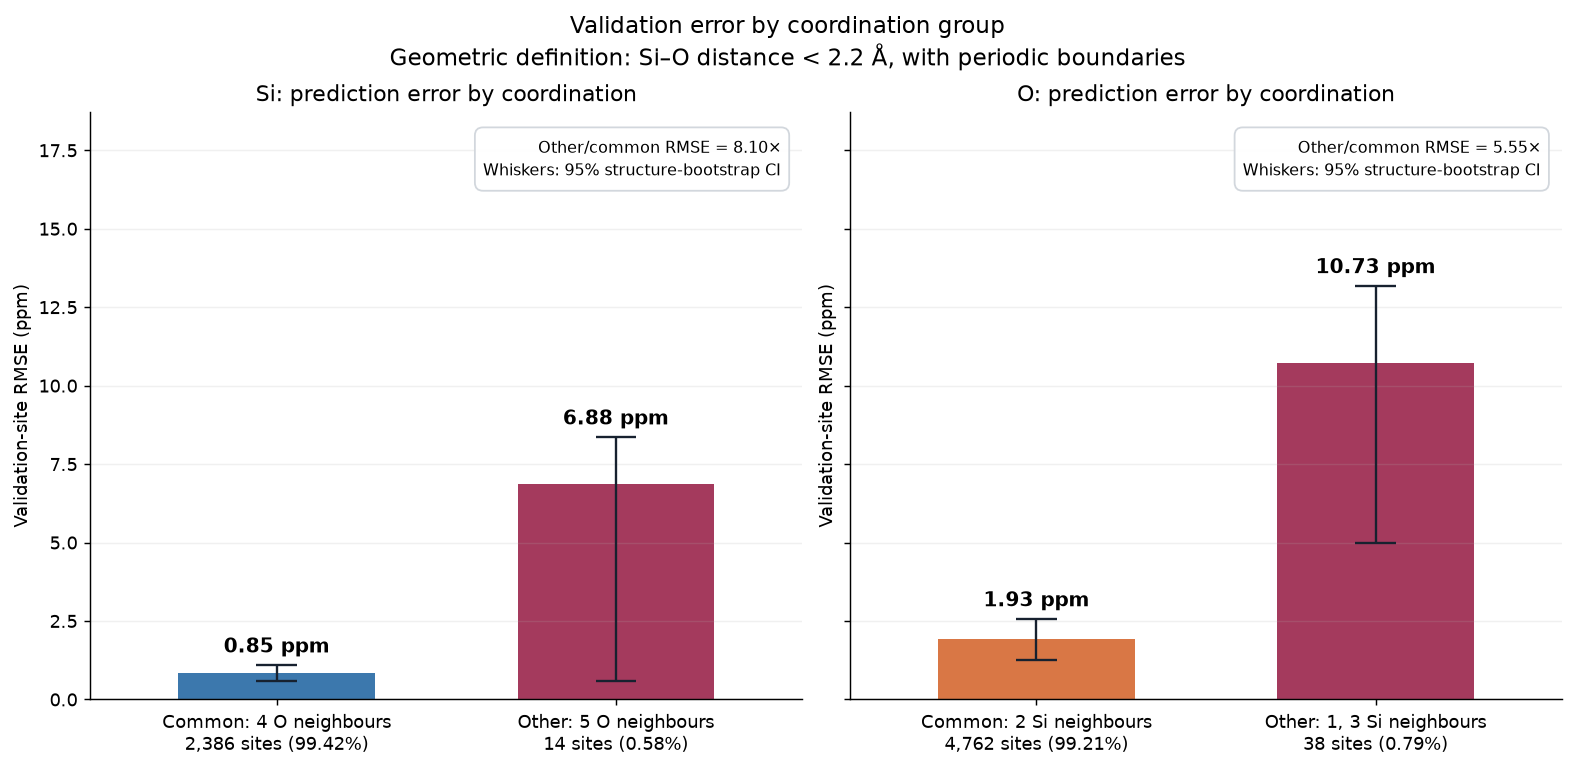

sites  structures  MAE_ppm  RMSE_ppm
element neighbours                                      
O       1              12          10   13.409    17.611
        2            4762          50    1.003     1.933
        3              26          13    3.751     5.001
Si      4            2386          50    0.501     0.849
        5              14           5    5.464     6.878

In [11]:
fig_coordination, axes = plt.subplots(1, 2, figsize=(12, 5.8), sharey=True, layout='constrained')
max_interval = coordination_metrics.RMSE_CI_upper_ppm.max()
for ax, element in zip(axes, ELEMENTS):
    table = coordination_metrics.loc[element].loc[['Common coordination', 'Other coordination']]
    values = table.RMSE_ppm.to_numpy()
    low, high = table.RMSE_CI_lower_ppm.to_numpy(), table.RMSE_CI_upper_ppm.to_numpy()
    positions = np.arange(2)
    ax.bar(positions, values, width=0.58, color=[COLOURS[element], '#9a244b'], alpha=0.9)
    # Draw percentile interval bounds directly (no assumption that they contain the point estimate).
    ax.vlines(positions, low, high, color='#17212f', linewidth=1.3)
    ax.hlines(low, positions-0.06, positions+0.06, color='#17212f', linewidth=1.3)
    ax.hlines(high, positions-0.06, positions+0.06, color='#17212f', linewidth=1.3)
    for x, value, upper in zip(positions, values, high):
        ax.annotate(f'{value:.2f} ppm', (x, max(value, upper)), xytext=(0, 7),
                    textcoords='offset points', ha='center', fontsize=11, fontweight='bold')
    neighbour = 'O' if element == 'Si' else 'Si'
    tick_labels = []
    for (_, row), kind in zip(table.iterrows(), ['Common', 'Other']):
        tick_labels.append(f'{kind}: {row.observed_neighbour_counts} {neighbour} neighbours\n'
                           f'{int(row.sites):,} sites ({row.percent_of_element_sites:.2f}%)')
    ax.set_xticks(positions, tick_labels, fontsize=10)
    ratio = values[1] / values[0]
    stats_box(ax, f'Other/common RMSE = {ratio:.2f}×\nWhiskers: 95% structure-bootstrap CI', fontsize=9)
    ax.set(title=f'{element}: prediction error by coordination', ylabel='Validation-site RMSE (ppm)',
           ylim=(0, max_interval * 1.42), xlim=(-0.55, 1.55))
    ax.grid(axis='y', alpha=0.18)
fig_coordination.suptitle(f'Validation error by coordination group\n'
                         f'Geometric definition: Si–O distance < {COORDINATION_CUTOFF:.1f} Å, with periodic boundaries',
                         fontsize=13)
plt.show()
print('Exact coordination categories (small groups require caution):')
display(coordination_detail.round(3))


## 10. Results and reproducibility record

These results quantify reproduction of the supplied **DFT isotropic shielding labels**. With a fixed reference and unit-magnitude sign conversion, shielding MAE/RMSE are unchanged when expressed as chemical-shift errors. A fitted slope would change their scale. No experimental referencing is estimated here.

Direct claims of superiority to published models would require the same nuclei, reference calculation settings, structural domain and validation split. The large Si/O baseline separation is why per-element results, rather than pooled correlation, are the headline.


In [12]:
lines = [f'**Best checkpoint: epoch {best_epoch} of {last_epoch}.** ',
         f"Validation evaluation: {len(structures['valid'])} structures and {len(validation_sites):,} atomic sites.", '']
for element in ELEMENTS:
    m = metrics.loc[('valid', element)]
    interval = intervals.loc[(element, 'RMSE_ppm')]
    lines.append(f"- **{element}:** MAE **{m.MAE_ppm:.3f} ppm**, RMSE **{m.RMSE_ppm:.3f} ppm**, "
                 f"bias {m.bias_ppm:+.3f} ppm, $R^2={m.R2:.4f}$. "
                 f"Structure-bootstrap RMSE interval: {interval.lower_95_ppm:.3f}–{interval.upper_95_ppm:.3f} ppm. "
                 f"RMSE is {m.RMSE_reduction_vs_baseline_pct:.1f}% below the elemental-mean baseline "
                 f"on the validation structures.")
lines += ['', 'These validation structures selected the checkpoint. Use these results for development, not as an independent final assessment. No test dataset was loaded.']
display(Markdown('\n'.join(lines)))

manifest = {
    'evaluation_utc': datetime.now(timezone.utc).isoformat(),
    'run': RUN_NAME, 'best_epoch_1based': best_epoch, 'last_epoch_1based': last_epoch,
    'target': 'MS_Iso_QM = trace(ms)/3; absolute isotropic shielding', 'units': 'ppm',
    'error_sign': 'prediction minus reference', 'reference': 'CASTEP/PBE labels in supplied XYZ files',
    'model_sha256': model_hash, 'best_checkpoint_sha256': sha256(RUN / 'checkpoints/best.ckpt'),
    'config_sha256': sha256(RUN / 'train-config.yaml'),
    'helper_sha256': sha256(PROJECT / 'extract_ms_isotropy.py'),
    'data_sha256': data_hashes, 'versions': versions, 'python': platform.python_version(),
    'device': 'cpu', 'dtype': 'float32 predictions; float64 metrics', 'torch_threads': THREADS,
    'site_counts': audit['sites'].to_dict(), 'structure_counts': audit['structures'].to_dict(),
    'bootstrap': {'unit': 'structure', 'resamples': 2000, 'seed': 42,
                  'limitation': 'Assumes independent structures; trajectory dependence not assessed.'},
    'coordination_diagnostic': {'cutoff_A': COORDINATION_CUTOFF, 'periodic': True,
        'groups': 'Si: 4 versus other O neighbours; O: 2 versus other Si neighbours',
        'split': 'valid', 'bootstrap_resamples': 2000, 'seed': 42},
    'corrections_applied': False, 'outliers_removed': False,
}
print(json.dumps(manifest, indent=2))
print('Tables remain available as metrics, sites, structure_metrics, intervals and audit.')


{
  "evaluation_utc": "2026-10-14T14:22:07.178200+00:00",
  "run": "TensorNequIP-NMR-Coord3x-9083627",
  "best_epoch_1based": 287,
  "last_epoch_1based": 300,
  "target": "MS_Iso_QM = trace(ms)/3; absolute isotropic shielding",
  "units": "ppm",
  "error_sign": "prediction minus reference",
  "reference": "CASTEP/PBE labels in supplied XYZ files",
  "model_sha256": "e6b96cb04593adc1761b682a0d070a34c49c3de329493ef39016074ca6b625e6",
  "best_checkpoint_sha256": "64f652c9275f83519bfb5f92eaf771e82d44920cac39fb1c88324a4f242b4199",
  "config_sha256": "937013dd35accfa52183d1399e78b7c924bdd80094569b3d336f61ce46088063",
  "helper_sha256": "4847dab4b6cbf7375eecdad2fe8aa68dc9b919b3e993e96d27f03c976c53a3cc",
  "data_sha256": {
    "train": "77de1ed9983781e906c35aa63d4f134a0777c6e38a933791c6db866f8b9c6fda",
    "valid": "e73ce6065ce6729d6549d5b30a4129634aaec84e3a2429c044d31d81020a4d11"
  },
  "versions": {
    "graph-pes": "1.0.2",
    "torch": "2.6.0",
    "e3nn": "0.4.4",
    "ase": "3.29.0",
   

**Best checkpoint: epoch 287 of 300.** 
Validation evaluation: 50 structures and 7,200 atomic sites.

- **Si:** MAE **0.529 ppm**, RMSE **0.997 ppm**, bias +0.022 ppm, $R^2=0.9879$. Structure-bootstrap RMSE interval: 0.602–1.388 ppm. RMSE is 89.0% below the elemental-mean baseline on the validation structures.
- **O:** MAE **1.048 ppm**, RMSE **2.149 ppm**, bias +0.013 ppm, $R^2=0.9895$. Structure-bootstrap RMSE interval: 1.359–2.923 ppm. RMSE is 89.8% below the elemental-mean baseline on the validation structures.

These validation structures selected the checkpoint. Use these results for development, not as an independent final assessment. No test dataset was loaded.

## 11. Comparison with the original unweighted-loss run

All evaluation metrics are unweighted. The 3× multiplier applies only during training. Baseline values below are embedded from the previously executed validation diagnostics.


In [13]:
from io import StringIO
baseline_metrics = pd.read_csv(StringIO('split,element,sites,structures,MAE_ppm,RMSE_ppm,bias_ppm,median_AE_ppm,p95_AE_ppm,max_AE_ppm,R2,baseline_RMSE_ppm,baseline_MAE_ppm,RMSE_reduction_vs_baseline_pct\nvalid,Si,2400,50,0.5378234529115237,1.096772975810769,-0.05797249955227871,0.3153489220312622,1.6081153147148284,16.13879821789061,0.9853543309560843,9.063184028783535,7.132281688174732,87.89859091101366\nvalid,O,4800,50,1.0711858237622558,2.2349634865462393,0.13115961317140312,0.6044246226171737,3.5174060249121246,42.041365324511716,0.9886167621071498,20.980587919037934,14.08948493196067,89.34746969355317\n')).set_index(['split', 'element'])
baseline_coordination = pd.read_csv(StringIO('element,group,observed_neighbour_counts,sites,percent_of_element_sites,structures_containing_group,MAE_ppm,RMSE_ppm,bias_ppm,median_AE_ppm,p95_AE_ppm,max_AE_ppm,R2,RMSE_CI_lower_ppm,RMSE_CI_upper_ppm,nonempty_bootstrap_resamples\nSi,Common coordination,4,2386,99.41666666666667,50,0.5004027131152429,0.8838369928095509,-0.031167812462149065,0.3140724338281018,1.5617670896093898,14.035897227343753,0.9899221474913085,0.6010195129701392,1.136009029420314,2000\nSi,Other coordination,5,14,0.5833333333333334,5,6.915386678191965,8.548683537257364,-4.6262570279129465,6.9773209762890644,14.363702915492196,16.13879821789061,0.3986959347065604,0.8463036242061169,9.627688736931507,1989\nO,Common coordination,2,4762,99.20833333333333,50,1.0183312348220654,1.943569548781131,0.10884389998387724,0.5995845038476659,3.2748484179335975,27.89121796291016,0.990416392190734,1.2399465210948315,2.577580513484806,2000\nO,Other coordination,"1, 3",38,0.7916666666666666,13,7.694700364109272,12.553066007988795,2.92767082893452,4.043579749628904,34.60625725671386,42.041365324511716,0.8968934126127021,5.879656112457789,15.550874562232401,2000\n')).set_index(['element', 'group'])
comparison = metrics[['MAE_ppm','RMSE_ppm','p95_AE_ppm','max_AE_ppm']].join(
    baseline_metrics[['MAE_ppm','RMSE_ppm','p95_AE_ppm','max_AE_ppm']], lsuffix='_3x', rsuffix='_original')
comparison['RMSE_change_pct'] = 100*(comparison.RMSE_ppm_3x/comparison.RMSE_ppm_original-1)
display(comparison.round(4))
coordination_comparison = coordination_metrics[['sites','MAE_ppm','RMSE_ppm']].join(
    baseline_coordination[['MAE_ppm','RMSE_ppm']], lsuffix='_3x', rsuffix='_original')
coordination_comparison['RMSE_change_pct'] = 100*(coordination_comparison.RMSE_ppm_3x/coordination_comparison.RMSE_ppm_original-1)
display(coordination_comparison.round(4))
print('Negative changes mean improvement. Original results are from the previously executed validation notebook for TensorNequIP-NMR-9065266. This is a single-run comparison, not a training-seed uncertainty estimate.')


Negative changes mean improvement. Original results are from the previously executed validation notebook for TensorNequIP-NMR-9065266. This is a single-run comparison, not a training-seed uncertainty estimate.


MAE_ppm_3x  RMSE_ppm_3x  p95_AE_ppm_3x  max_AE_ppm_3x  MAE_ppm_original  RMSE_ppm_original  p95_AE_ppm_original  max_AE_ppm_original  \
split element                                                                                                                                         
valid Si           0.5295       0.9967         1.5962        12.9462            0.5378             1.0968               1.6081              16.1388   
      O            1.0484       2.1489         3.2034        34.1242            1.0712             2.2350               3.5174              42.0414   

               RMSE_change_pct  
split element                   
valid Si               -9.1288  
      O                -3.8491

sites  MAE_ppm_3x  RMSE_ppm_3x  MAE_ppm_original  RMSE_ppm_original  RMSE_change_pct
element group                                                                                                    
Si      Common coordination   2386      0.5005       0.8495            0.5004             0.8838          -3.8906
        Other coordination      14      5.4637       6.8780            6.9154             8.5487         -19.5433
O       Common coordination   4762      1.0025       1.9331            1.0183             1.9436          -0.5411
        Other coordination      38      6.8010      10.7262            7.6947            12.5531         -14.5531

## Findings from this run

Best checkpoint: epoch **287/300**. Fresh inference on **50 validation structures (7,200 sites)**; exported model matches the best checkpoint. Dataset SHA-256 hashes match the original evaluation. No test data or cached predictions were opened.

Compared with the original model, overall RMSE decreases from **1.097 to 0.997 ppm for Si (9.1%)** and **2.235 to 2.149 ppm for O (3.8%)**. Defect-site RMSE decreases from **8.549 to 6.878 ppm for five-coordinate Si (19.5%)** and **12.553 to 10.726 ppm for one/three-coordinate O (14.6%)**. Normally coordinated-site RMSE also decreases slightly. Maximum absolute errors decrease from **16.139 to 12.946 ppm (Si)** and **42.041 to 34.124 ppm (O)**.

This supports continuing the coordination-weighting experiment, but does not establish a reproducible effect across training seeds. The defect cohorts remain small (14 Si sites in five structures; 38 O sites in 13 structures), and this validation set selected the checkpoints. The remaining large errors warrant inspecting the per-site and exact-coordination tables.
